In [ ]:
!git clone https://github.com/ahmadsss/xai-series.git
!git clone https://github.com/SartajBhuvaji/Brain-Tumor-Classification-DataSet.git
!mkdir -p xai-series/data/brain_mri/training xai-series/data/brain_mri/testing
!cp -r Brain-Tumor-Classification-DataSet/Training/* xai-series/data/brain_mri/training/
!cp -r Brain-Tumor-Classification-DataSet/Testing/*  xai-series/data/brain_mri/testing/
%cd xai-series

Cloning into 'xai-series'...
remote: Enumerating objects: 3077, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 3077 (delta 12), reused 9 (delta 9), pack-reused 3059 (from 1)
Receiving objects: 100% (3077/3077), 79.33 MiB | 36.79 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Cloning into 'Brain-Tumor-Classification-DataSet'...
remote: Enumerating objects: 3039, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 3039 (delta 0), reused 0 (delta 0), pack-reused 3033 (from 1)
Receiving objects: 100% (3039/3039), 79.24 MiB | 35.95 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/xai-series


True
tensor(1.4533, device='cuda:0', grad_fn=<NllLossBackward0>)
tensor(1.4444, device='cuda:0', grad_fn=<NllLossBackward0>)
tensor(1.3360, device='cuda:0', grad_fn=<NllLossBackward0>)
tensor(1.3234, device='cuda:0', grad_fn=<NllLossBackward0>)
tensor(1.3334, device='cuda:0', grad_fn=<NllLossBackward0>)
tensor(1.3122, device='cuda:0', grad_fn=<NllLossBackward0>)
tensor(1.3078, device='cuda:0', grad_fn=<NllLossBackward0>)
tensor(1.2966, device='cuda:0', grad_fn=<NllLossBackward0>)
tensor(1.2980, device='cuda:0', grad_fn=<NllLossBackward0>)
tensor(1.1673, device='cuda:0', grad_fn=<NllLossBackward0>)
tensor(1.2282, device='cuda:0', grad_fn=<NllLossBackward0>)
tensor(1.2614, device='cuda:0', grad_fn=<NllLossBackward0>)
tensor(1.2351, device='cuda:0', grad_fn=<NllLossBackward0>)
tensor(1.2625, device='cuda:0', grad_fn=<NllLossBackward0>)
tensor(1.2575, device='cuda:0', grad_fn=<NllLossBackward0>)
tensor(1.1833, device='cuda:0', grad_fn=<NllLossBackward0>)
tensor(1.1475, device='cuda:0', gra

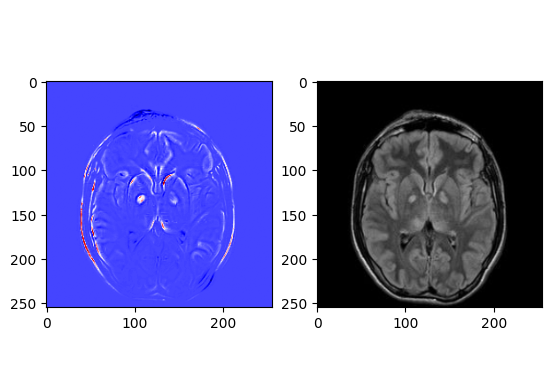

In [ ]:
# %% Imports
import torch
import torch.nn as nn
import torchvision
import torchvision.models as models
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import torch.optim as optim
import copy
import pandas as pd

# Set GPU device
print(torch.cuda.is_available())
device = torch.device("cuda:0")


# %% Load data
TRAIN_ROOT = "data/brain_mri/training"
TEST_ROOT = "data/brain_mri/testing"
train_dataset = torchvision.datasets.ImageFolder(root=TRAIN_ROOT)
test_dataset = torchvision.datasets.ImageFolder(root=TRAIN_ROOT)


# %% Building the model
class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()
        self.vgg16 = models.vgg16(pretrained=True)

        # Replace output layer according to our problem
        in_feats = self.vgg16.classifier[6].in_features
        self.vgg16.classifier[6] = nn.Linear(in_feats, 4)

    def forward(self, x):
        x = self.vgg16(x)
        return x

model = CNNModel()
model.to(device)
model

# %% Prepare data for pretrained model
train_dataset = torchvision.datasets.ImageFolder(
        root=TRAIN_ROOT,
        transform=transforms.Compose([
                      transforms.Resize((255,255)),
                      transforms.ToTensor()
        ])
)

test_dataset = torchvision.datasets.ImageFolder(
        root=TEST_ROOT,
        transform=transforms.Compose([
                      transforms.Resize((255,255)),
                      transforms.ToTensor()
        ])
)

#train_dataset[0][0].permute(1,2,0)

# %% Create data loaders
batch_size = 32
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)
test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=True
)

# %% Train
cross_entropy_loss = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.00001)
epochs = 10

# Iterate x epochs over the train data
for epoch in range(epochs):
    for i, batch in enumerate(train_loader, 0):
        inputs, labels = batch
        inputs = inputs.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        # Labels are automatically one-hot-encoded
        loss = cross_entropy_loss(outputs, labels)
        loss.backward()
        optimizer.step()
        print(loss)

# %% Inspect predictions for first batch
import pandas as pd
inputs, labels = next(iter(test_loader))
inputs = inputs.to(device)
labels = labels.numpy()
outputs = model(inputs).max(1).indices.detach().cpu().numpy()
comparison = pd.DataFrame()
print("Batch accuracy: ", (labels==outputs).sum()/len(labels))
comparison["labels"] = labels

comparison["outputs"] = outputs
comparison

# %% Layerwise relevance propagation for VGG16
# For other CNN architectures this code might become more complex
# Source: https://git.tu-berlin.de/gmontavon/lrp-tutorial
# http://iphome.hhi.de/samek/pdf/MonXAI19.pdf

def new_layer(layer, g):
    """Clone a layer and pass its parameters through the function g."""
    layer = copy.deepcopy(layer)
    try: layer.weight = torch.nn.Parameter(g(layer.weight))
    except AttributeError: pass
    try: layer.bias = torch.nn.Parameter(g(layer.bias))
    except AttributeError: pass
    return layer

def dense_to_conv(layers):
    """ Converts a dense layer to a conv layer """
    newlayers = []
    for i,layer in enumerate(layers):
        if isinstance(layer, nn.Linear):
            newlayer = None
            if i == 0:
                m, n = 512, layer.weight.shape[0]
                newlayer = nn.Conv2d(m,n,7)
                newlayer.weight = nn.Parameter(layer.weight.reshape(n,m,7,7))
            else:
                m,n = layer.weight.shape[1],layer.weight.shape[0]
                newlayer = nn.Conv2d(m,n,1)
                newlayer.weight = nn.Parameter(layer.weight.reshape(n,m,1,1))
            newlayer.bias = nn.Parameter(layer.bias)
            newlayers += [newlayer]
        else:
            newlayers += [layer]
    return newlayers

def get_linear_layer_indices(model):
    offset = len(model.vgg16._modules['features']) + 1
    indices = []
    for i, layer in enumerate(model.vgg16._modules['classifier']):
        if isinstance(layer, nn.Linear):
            indices.append(i)
    indices = [offset + val for val in indices]
    return indices

def apply_lrp_on_vgg16(model, image):
    image = torch.unsqueeze(image, 0)
    # >>> Step 1: Extract layers
    layers = list(model.vgg16._modules['features']) \
                + [model.vgg16._modules['avgpool']] \
                + dense_to_conv(list(model.vgg16._modules['classifier']))
    linear_layer_indices = get_linear_layer_indices(model)
    # >>> Step 2: Propagate image through layers and store activations
    n_layers = len(layers)
    activations = [image] + [None] * n_layers # list of activations

    for layer in range(n_layers):
        if layer in linear_layer_indices:
            if layer == 32:
                activations[layer] = activations[layer].reshape((1, 512, 7, 7))
        activation = layers[layer].forward(activations[layer])
        if isinstance(layers[layer], torch.nn.modules.pooling.AdaptiveAvgPool2d):
            activation = torch.flatten(activation, start_dim=1)
        activations[layer+1] = activation

    # >>> Step 3: Replace last layer with one-hot-encoding
    # output_activation = activations[-1].detach().cpu().numpy()
    # max_activation = output_activation.max()
    # one_hot_output = [val if val == max_activation else 0
    #                     for val in output_activation[0]]

    # activations[-1] = torch.FloatTensor([one_hot_output]).to(device)
    #THE ABOVE STEP 3 IS NOT COMPATIBLE WITH THE NEW NUMPY VERSION, BELOW
    #IS THE FIX
    logits = activations[-1].detach()
    target = logits.argmax(dim=1)
    one_hot = torch.zeros_like(logits)
    one_hot[0, target] = logits[0, target]
    activations[-1] = one_hot.to(device)

    # >>> Step 4: Backpropagate relevance scores
    relevances = [None] * n_layers + [activations[-1]]
    # Iterate over the layers in reverse order
    for layer in range(0, n_layers)[::-1]:
        current = layers[layer]
        # Treat max pooling layers as avg pooling
        if isinstance(current, torch.nn.MaxPool2d):
            layers[layer] = torch.nn.AvgPool2d(2)
            current = layers[layer]
        if isinstance(current, torch.nn.Conv2d) or \
           isinstance(current, torch.nn.AvgPool2d) or\
           isinstance(current, torch.nn.Linear):
            activations[layer] = activations[layer].data.requires_grad_(True)

            # Apply variants of LRP depending on the depth
            # see: https://link.springer.com/chapter/10.1007%2F978-3-030-28954-6_10
            # Lower layers, LRP-gamma >> Favor positive contributions (activations)
            if layer <= 16:       rho = lambda p: p + 0.25*p.clamp(min=0); incr = lambda z: z+1e-9
            # Middle layers, LRP-epsilon >> Remove some noise / Only most salient factors survive
            if 17 <= layer <= 30: rho = lambda p: p;                       incr = lambda z: z+1e-9+0.25*((z**2).mean()**.5).data
            # Upper Layers, LRP-0 >> Basic rule
            if layer >= 31:       rho = lambda p: p;                       incr = lambda z: z+1e-9

            # Transform weights of layer and execute forward pass
            z = incr(new_layer(layers[layer],rho).forward(activations[layer]))
            # Element-wise division between relevance of the next layer and z
            s = (relevances[layer+1]/z).data
            # Calculate the gradient and multiply it by the activation
            (z * s).sum().backward();
            c = activations[layer].grad
            # Assign new relevance values
            relevances[layer] = (activations[layer]*c).data
        else:
            relevances[layer] = relevances[layer+1]

    # >>> Potential Step 5: Apply different propagation rule for pixels
    return relevances[0]

# %%
# Calculate relevances for first image in this test batch
image_id = 31
image_relevances = apply_lrp_on_vgg16(model, inputs[image_id])
image_relevances = image_relevances.permute(0,2,3,1).detach().cpu().numpy()[0]
image_relevances = np.interp(image_relevances, (image_relevances.min(),
                                                image_relevances.max()),
                                                (0, 1))
# Show relevances
pred_label = list(test_dataset.class_to_idx.keys())[
             list(test_dataset.class_to_idx.values())
            .index(labels[image_id])]
if outputs[image_id] == labels[image_id]:
    print("Groundtruth for this image: ", pred_label)

    # Plot images next to each other
    plt.axis('off')
    plt.subplot(1,2,1)
    plt.imshow(image_relevances[:,:,0], cmap="seismic")
    plt.subplot(1,2,2)
    plt.imshow(inputs[image_id].permute(1,2,0).detach().cpu().numpy())
    plt.show()
else:
    print("This image is not classified correctly.")

# %%


In [ ]:
model.eval()

CNNModel(
  (vgg16): VGG(
    (features): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (6): ReLU(inplace=True)
      (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (8): ReLU(inplace=True)
      (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (11): ReLU(inplace=True)
      (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (13): ReLU(inplace=True)
      (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (15): ReLU(inplace=True)
      (16):

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
torch.save(model.state_dict(), "vgg16_brain_mri_baseline.pth")
!cp vgg16_brain_mri_baseline.pth /content/drive/MyDrive/
!ls -lh /content/drive/MyDrive/vgg16_brain_mri_baseline.pth

Mounted at /content/drive
-rw------- 1 root root 513M Nov 26 03:00 /content/drive/MyDrive/vgg16_brain_mri_baseline.pth


device: cuda:0 | torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | numpy 2.4.6
class_to_idx: {'glioma_tumor': 0, 'meningioma_tumor': 1, 'no_tumor': 2, 'pituitary_tumor': 3}
train images: 2870 | test images: 394
Test images evaluated: 394 | accuracy: 0.7919
                  precision    recall  f1-score   support

    glioma_tumor      1.000     0.240     0.387       100
meningioma_tumor      0.691     0.991     0.814       115
        no_tumor      0.802     1.000     0.890       105
 pituitary_tumor      0.932     0.932     0.932        74

        accuracy                          0.792       394
       macro avg      0.856     0.791     0.756       394
    weighted avg      0.844     0.792     0.748       394



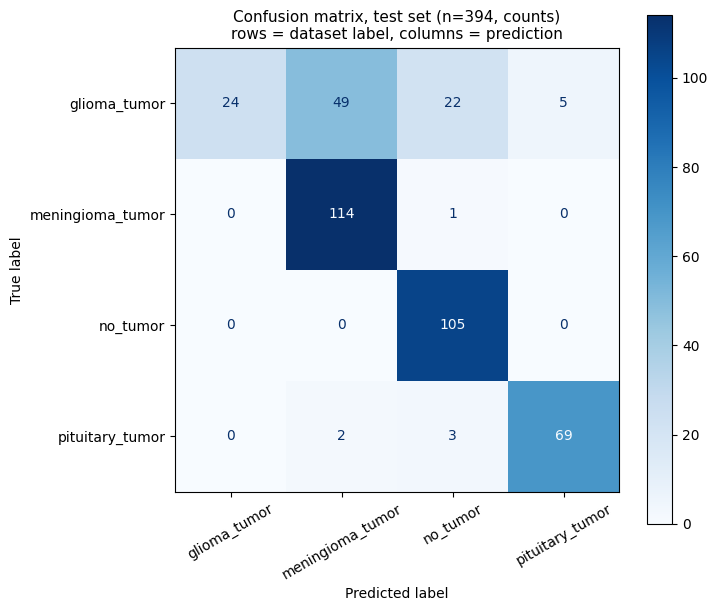

{'correct_glioma_tumor': 26, 'correct_meningioma_tumor': 100, 'correct_no_tumor': 215, 'correct_pituitary_tumor': 320, 'error_1_glioma_tumor_as_meningioma_tumor': 0, 'error_2_glioma_tumor_as_meningioma_tumor': 1, 'error_3_glioma_tumor_as_no_tumor': 2}


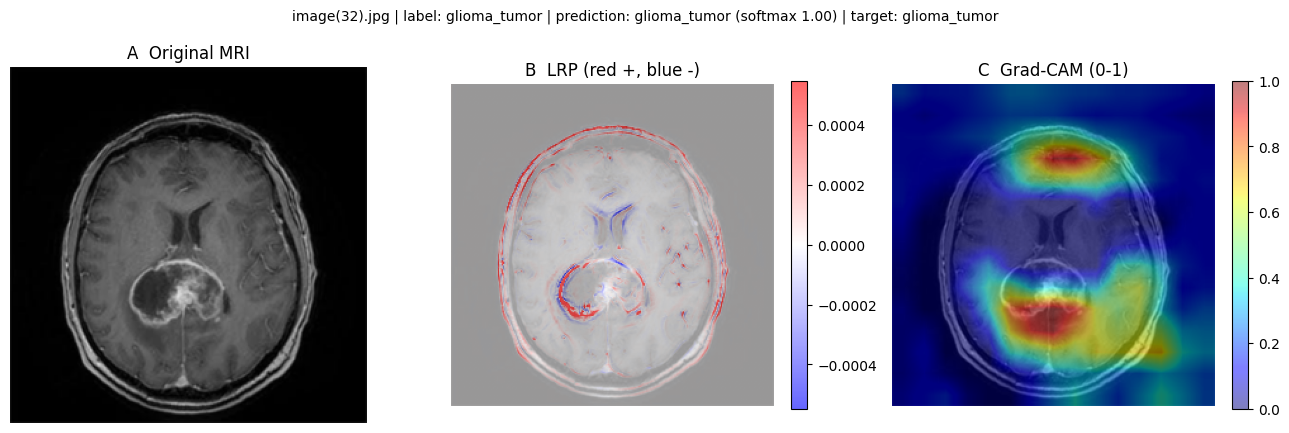

data/brain_mri/testing/glioma_tumor/image(32).jpg


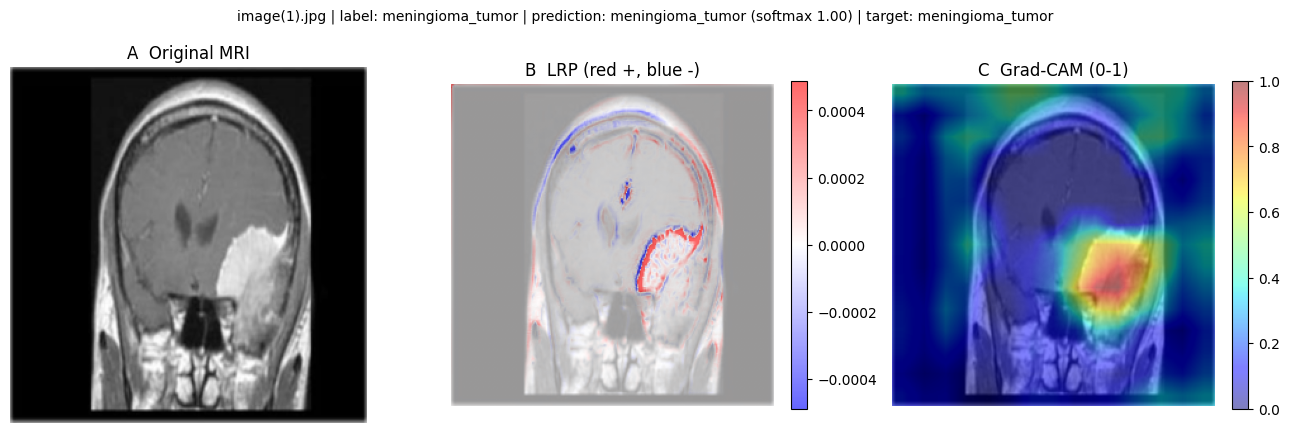

data/brain_mri/testing/meningioma_tumor/image(1).jpg


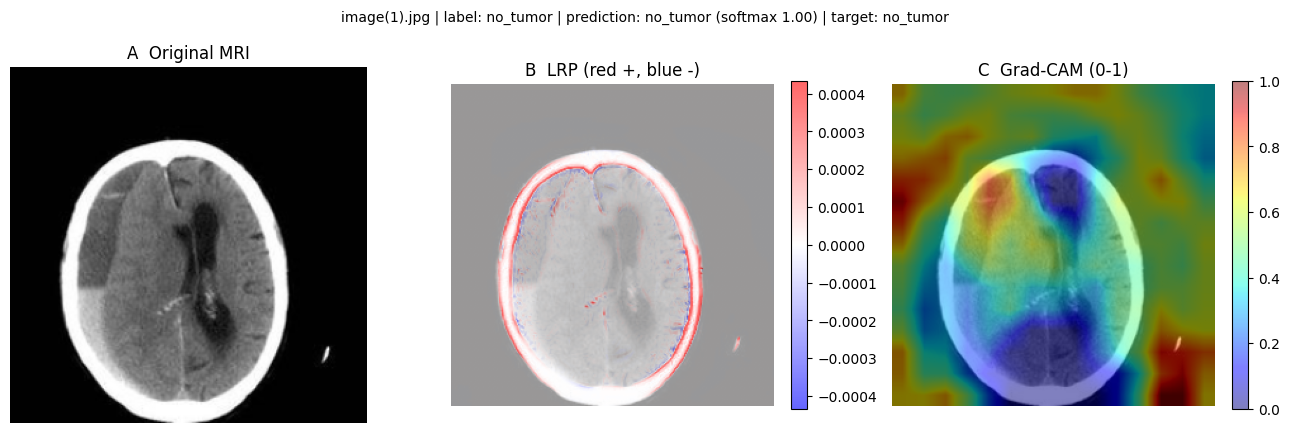

data/brain_mri/testing/no_tumor/image(1).jpg


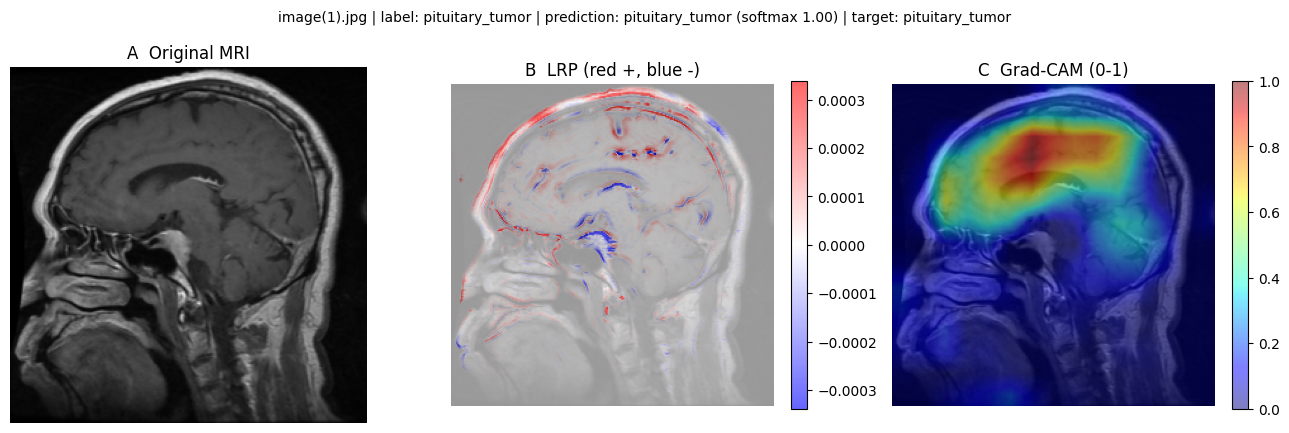

data/brain_mri/testing/pituitary_tumor/image(1).jpg


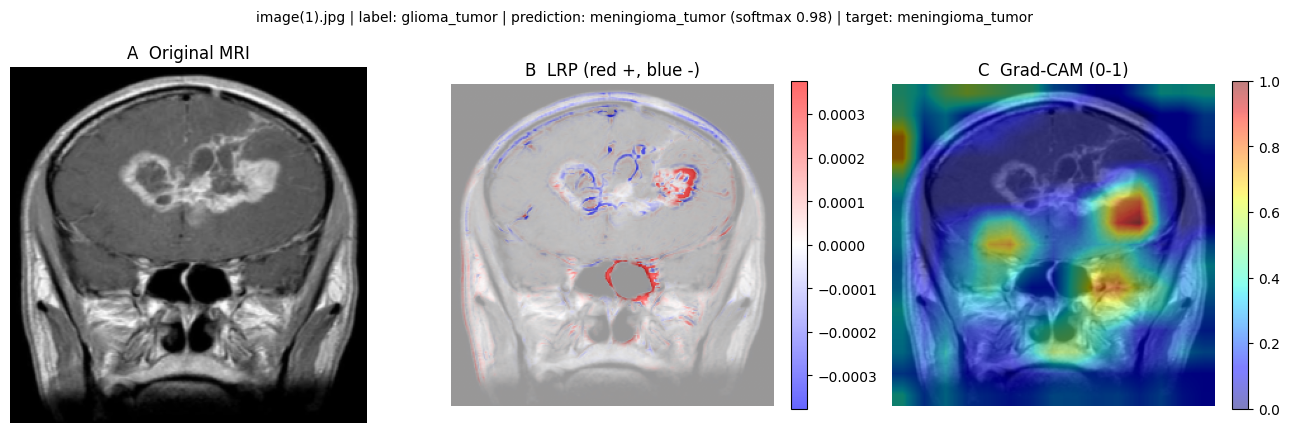

data/brain_mri/testing/glioma_tumor/image(1).jpg


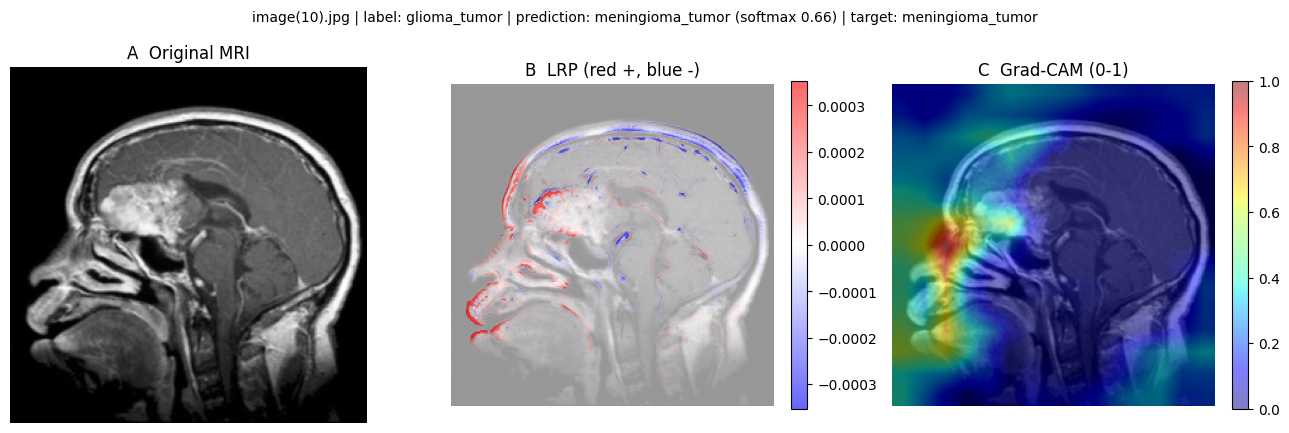

data/brain_mri/testing/glioma_tumor/image(10).jpg


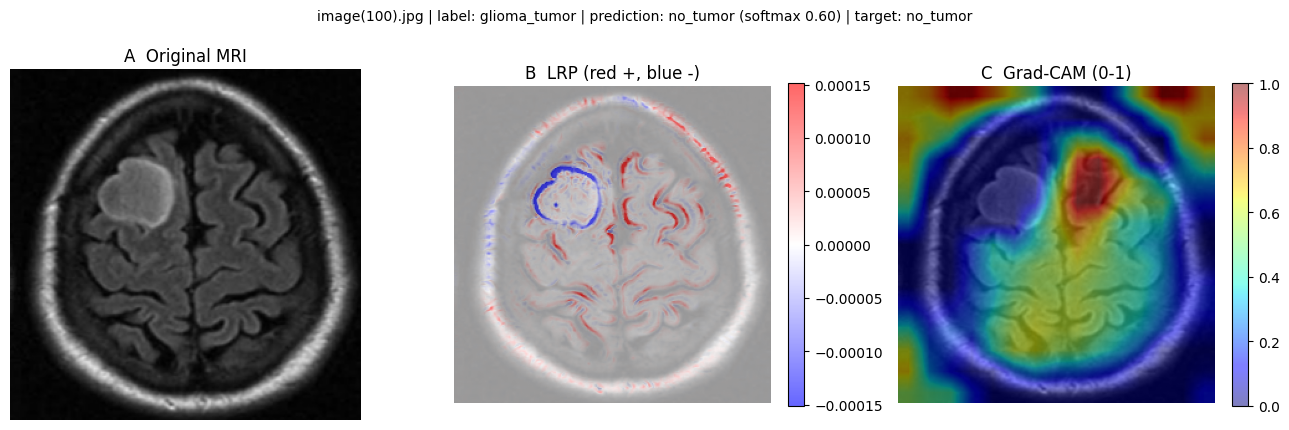

data/brain_mri/testing/glioma_tumor/image(100).jpg


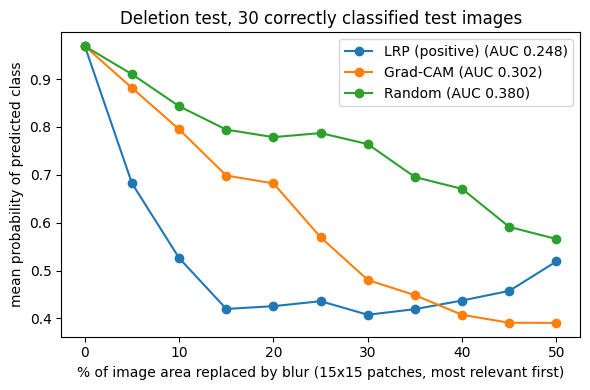

In [ ]:
# %% [markdown]
# # Brain MRI: LRP + Grad-CAM on the VGG16 checkpoint trained by 05_lrp.py
# Run in Colab (GPU) from inside the xai-series folder, after data/brain_mri/{training,testing}
# exist and vgg16_brain_mri_baseline.pth has been placed in the working directory.
# Preprocessing is deliberately identical to 05_lrp.py (Resize 255x255, ToTensor, NO ImageNet
# normalisation) because the checkpoint was trained that way.

# %% Imports and setup
import os, copy, random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.models as models, torchvision.transforms as transforms
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__, "| torchvision", torchvision.__version__, "| numpy", np.__version__)

TRAIN_ROOT = "data/brain_mri/training"
TEST_ROOT = "data/brain_mri/testing"
CKPT = "vgg16_brain_mri_baseline.pth"
os.makedirs("figures", exist_ok=True)

# %% Data (test loader is NOT shuffled so indices are stable and reproducible)
tf = transforms.Compose([transforms.Resize((255, 255)), transforms.ToTensor()])
train_dataset = torchvision.datasets.ImageFolder(TRAIN_ROOT, transform=tf)
test_dataset = torchvision.datasets.ImageFolder(TEST_ROOT, transform=tf)
assert train_dataset.class_to_idx == test_dataset.class_to_idx, "class mappings differ"
class_names = test_dataset.classes
print("class_to_idx:", test_dataset.class_to_idx)
print("train images:", len(train_dataset), "| test images:", len(test_dataset))
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)

# %% Model (same definition as 05_lrp.py) + checkpoint
class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.vgg16 = models.vgg16(weights=None)  # weights come from the checkpoint
        self.vgg16.classifier[6] = nn.Linear(self.vgg16.classifier[6].in_features, 4)
    def forward(self, x):
        return self.vgg16(x)

model = CNNModel()
model.load_state_dict(torch.load(CKPT, map_location=device))
model.to(device).eval()   # eval(): disables dropout for prediction and explanations

# %% Full test-set evaluation
all_pred, all_true, all_prob = [], [], []
with torch.no_grad():
    for x, y in test_loader:
        p = F.softmax(model(x.to(device)), dim=1).cpu()
        all_prob.append(p); all_pred.append(p.argmax(1)); all_true.append(y)
pred = torch.cat(all_pred).numpy(); true = torch.cat(all_true).numpy(); prob = torch.cat(all_prob).numpy()
print("Test images evaluated:", len(true), "| accuracy: %.4f" % (pred == true).mean())
print(classification_report(true, pred, target_names=class_names, digits=3))
cm = confusion_matrix(true, pred)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=30, cmap="Blues")
ax.set_title(f"Confusion matrix, test set (n={len(true)}, counts)\nrows = dataset label, columns = prediction", fontsize=11)
plt.tight_layout(); plt.savefig("figures/confusion_matrix.png", dpi=200); plt.show()

# %% LRP (starter code from 05_lrp.py; changes marked CHANGED)
def new_layer(layer, g):
    layer = copy.deepcopy(layer)
    try: layer.weight = torch.nn.Parameter(g(layer.weight))
    except AttributeError: pass
    try: layer.bias = torch.nn.Parameter(g(layer.bias))
    except AttributeError: pass
    return layer

def dense_to_conv(layers):
    newlayers = []
    for i, layer in enumerate(layers):
        if isinstance(layer, nn.Linear):
            if i == 0:
                m, n = 512, layer.weight.shape[0]
                newlayer = nn.Conv2d(m, n, 7)
                newlayer.weight = nn.Parameter(layer.weight.reshape(n, m, 7, 7))
            else:
                m, n = layer.weight.shape[1], layer.weight.shape[0]
                newlayer = nn.Conv2d(m, n, 1)
                newlayer.weight = nn.Parameter(layer.weight.reshape(n, m, 1, 1))
            newlayer.bias = nn.Parameter(layer.bias)
            newlayers += [newlayer]
        else:
            newlayers += [layer]
    return newlayers

def get_linear_layer_indices(model):
    offset = len(model.vgg16._modules['features']) + 1
    return [offset + i for i, l in enumerate(model.vgg16._modules['classifier']) if isinstance(l, nn.Linear)]

def lrp_vgg16(model, image, target=None):
    """Returns (relevance HxWx3 numpy, explained class index). image: 3xHxW tensor.
    CHANGED: target class can be chosen (default = predicted class); one-hot built in torch."""
    image = torch.unsqueeze(image, 0).to(device)
    layers = list(model.vgg16._modules['features']) + [model.vgg16._modules['avgpool']] \
             + dense_to_conv(list(model.vgg16._modules['classifier']))
    linear_layer_indices = get_linear_layer_indices(model)
    n_layers = len(layers)
    activations = [image] + [None] * n_layers
    with torch.no_grad():
        for layer in range(n_layers):
            if layer in linear_layer_indices and layer == 32:
                activations[layer] = activations[layer].reshape((1, 512, 7, 7))
            activation = layers[layer].forward(activations[layer])
            if isinstance(layers[layer], torch.nn.modules.pooling.AdaptiveAvgPool2d):
                activation = torch.flatten(activation, start_dim=1)
            activations[layer + 1] = activation
    # CHANGED: Step 3 in torch (original raised TypeError under NumPy 2.x)
    logits = activations[-1].detach()
    t = int(logits.argmax(1)) if target is None else int(target)
    one_hot = torch.zeros_like(logits)
    one_hot[0, t] = logits[0, t]
    activations[-1] = one_hot.to(device)

    relevances = [None] * n_layers + [activations[-1]]
    for layer in range(0, n_layers)[::-1]:
        current = layers[layer]
        if isinstance(current, torch.nn.MaxPool2d):
            layers[layer] = torch.nn.AvgPool2d(2); current = layers[layer]
        if isinstance(current, (torch.nn.Conv2d, torch.nn.AvgPool2d, torch.nn.Linear)):
            activations[layer] = activations[layer].data.requires_grad_(True)
            if layer <= 16:       rho = lambda p: p + 0.25 * p.clamp(min=0); incr = lambda z: z + 1e-9           # LRP-gamma
            if 17 <= layer <= 30: rho = lambda p: p;                         incr = lambda z: z + 1e-9 + 0.25 * ((z ** 2).mean() ** .5).data  # LRP-epsilon
            if layer >= 31:       rho = lambda p: p;                         incr = lambda z: z + 1e-9           # LRP-0
            z = incr(new_layer(layers[layer], rho).forward(activations[layer]))
            s = (relevances[layer + 1] / z).data
            (z * s).sum().backward()
            c = activations[layer].grad
            relevances[layer] = (activations[layer] * c).data
        else:
            relevances[layer] = relevances[layer + 1]
    return relevances[0].permute(0, 2, 3, 1).detach().cpu().numpy()[0], t

# %% Grad-CAM (own implementation, no hooks; target layer = last conv block, features[29] = ReLU after conv 28)
def gradcam_vgg16(model, image, target=None):
    x = image.unsqueeze(0).to(device)
    vgg = model.vgg16
    a = vgg.features[:30](x)                       # activations of the last conv layer (after ReLU)
    out = vgg.classifier(torch.flatten(vgg.avgpool(vgg.features[30](a)), 1))
    t = int(out.argmax(1)) if target is None else int(target)
    grads = torch.autograd.grad(out[0, t], a)[0]   # d score_t / d activations (raw logit)
    w = grads.mean(dim=(2, 3), keepdim=True)       # channel weights
    cam = F.relu((w * a).sum(1, keepdim=True))     # negative evidence discarded
    cam = F.interpolate(cam, size=image.shape[1:], mode="bilinear", align_corners=False)[0, 0]
    cam = cam.detach().cpu().numpy()
    return cam / (cam.max() + 1e-12), t

# %% Display helpers (signed LRP: symmetric colour scale so white = zero relevance)
def lrp_map(rel):                    # sum over RGB channels, keep sign
    return rel.sum(axis=2)

def show_case(idx, fname):
    x, y = test_dataset[idx]
    p = int(pred[idx]); conf = prob[idx, p]
    rel, t = lrp_vgg16(model, x, target=p)
    cam, _ = gradcam_vgg16(model, x, target=p)
    r = lrp_map(rel); v = np.percentile(np.abs(r), 99.5)
    img = x.permute(1, 2, 0).numpy()
    fig, ax = plt.subplots(1, 3, figsize=(13, 4.6))
    ax[0].imshow(img); ax[0].set_title("A  Original MRI")
    ax[1].imshow(img.mean(2), cmap="gray")
    im1 = ax[1].imshow(r, cmap="bwr", vmin=-v, vmax=v, alpha=0.6); ax[1].set_title("B  LRP (red +, blue -)")
    ax[2].imshow(img.mean(2), cmap="gray")
    im2 = ax[2].imshow(cam, cmap="jet", vmin=0, vmax=1, alpha=0.5); ax[2].set_title("C  Grad-CAM (0-1)")
    for a_ in ax: a_.axis("off")
    plt.colorbar(im1, ax=ax[1], fraction=0.046); plt.colorbar(im2, ax=ax[2], fraction=0.046)
    path = test_dataset.samples[idx][0]
    fig.suptitle(f"{os.path.basename(path)} | label: {class_names[y]} | prediction: {class_names[p]} "
                 f"(softmax {conf:.2f}) | target: {class_names[p]}", fontsize=10)
    plt.tight_layout(); plt.savefig(fname, dpi=200); plt.show()
    print(path)

# %% Case selection: first correct image of each class + first misclassified images
cases = {}
for c in range(len(class_names)):
    ok = np.where((true == c) & (pred == c))[0]
    if len(ok): cases[f"correct_{class_names[c]}"] = int(ok[0])
wrong = np.where(pred != true)[0]
for k, i in enumerate(wrong[:3]):
    cases[f"error_{k+1}_{class_names[true[i]]}_as_{class_names[pred[i]]}"] = int(i)
print(cases)
for name, idx in cases.items():
    show_case(idx, f"figures/case_{name}.png")

# %% Quantitative bonus: deletion test (remove most-relevant regions, watch the predicted-class probability fall)
# Deletion works on 15x15 patches (255 = 17 x 15) and replaces them with a heavily blurred copy of the image.
# Pixel-wise zeroing was tried first but created salt-and-pepper noise that the random baseline exploited
# (out-of-distribution artefact). Tests faithfulness to the MODEL, not diagnostic validity.
import torchvision.transforms.functional as TF
PATCH = 15

def deletion_curve(img, mapping, cls, fracs):
    H, W = mapping.shape
    score = F.avg_pool2d(torch.as_tensor(mapping, dtype=torch.float32)[None, None], PATCH)[0, 0]  # 17x17
    order = torch.argsort(score.flatten(), descending=True)
    blurred = TF.gaussian_blur(img, kernel_size=51, sigma=20.0)
    out = []
    for f in fracs:
        m = torch.ones(score.numel()); m[order[:int(round(f * score.numel()))]] = 0
        m = m.reshape(score.shape).repeat_interleave(PATCH, 0).repeat_interleave(PATCH, 1)[:H, :W]
        xm = img * m + blurred * (1 - m)
        with torch.no_grad():
            out.append(F.softmax(model(xm[None].to(device)), 1)[0, cls].item())
    return np.array(out)

def auc(y, x): return float(np.sum((y[1:] + y[:-1]) / 2 * np.diff(x)))

fracs = np.linspace(0, 0.5, 11)
ok_idx = np.where(pred == true)[0]
sel = np.random.RandomState(SEED).choice(ok_idx, size=min(30, len(ok_idx)), replace=False)
res = {"LRP (positive)": [], "Grad-CAM": [], "Random": []}
for i in sel:
    x, _ = test_dataset[int(i)]; c = int(pred[i])
    rel, _ = lrp_vgg16(model, x, target=c); cam, _ = gradcam_vgg16(model, x, target=c)
    res["LRP (positive)"].append(deletion_curve(x, np.clip(lrp_map(rel), 0, None), c, fracs))
    res["Grad-CAM"].append(deletion_curve(x, cam, c, fracs))
    res["Random"].append(deletion_curve(x, np.random.RandomState(int(i)).rand(*cam.shape), c, fracs))
plt.figure(figsize=(6, 4))
for k, v in res.items():
    m = np.mean(v, 0); plt.plot(fracs * 100, m, marker="o", label=f"{k} (AUC {auc(m, fracs):.3f})")
plt.xlabel("% of image area replaced by blur (15x15 patches, most relevant first)"); plt.ylabel("mean probability of predicted class")
plt.title(f"Deletion test, {len(sel)} correctly classified test images"); plt.legend(); plt.tight_layout()
plt.savefig("figures/deletion_test.png", dpi=200); plt.show()
# Lower AUC = faster drop = the map found pixels the model relies on more.


In [ ]:
!zip -r figures.zip figures

  adding: figures/ (stored 0%)
  adding: figures/deletion_test.png (deflated 7%)
  adding: figures/case_correct_pituitary_tumor.png (deflated 1%)
  adding: figures/case_correct_no_tumor.png (deflated 2%)
  adding: figures/case_correct_meningioma_tumor.png (deflated 1%)
  adding: figures/case_error_2_glioma_tumor_as_meningioma_tumor.png (deflated 1%)
  adding: figures/case_error_1_glioma_tumor_as_meningioma_tumor.png (deflated 1%)
  adding: figures/case_error_3_glioma_tumor_as_no_tumor.png (deflated 1%)
  adding: figures/case_correct_glioma_tumor.png (deflated 1%)
  adding: figures/deletion_test_v1_pixel_zero.png (deflated 7%)
  adding: figures/confusion_matrix.png (deflated 16%)


In [ ]:
%cd /content/xai-series
!git pull
!git log --oneline -1

/content/xai-series
Updating 8ea9a5e..d2f7c68
Fast-forward
 06_xai_brain_mri.py                                |  27 ++++++++++++-------
 figures/case_correct_glioma_tumor.png              | Bin 0 -> 895955 bytes
 figures/case_correct_meningioma_tumor.png          | Bin 0 -> 835452 bytes
 figures/case_correct_no_tumor.png                  | Bin 0 -> 823372 bytes
 figures/case_correct_pituitary_tumor.png           | Bin 0 -> 1107594 bytes
 ...se_error_1_glioma_tumor_as_meningioma_tumor.png | Bin 0 -> 1129904 bytes
 ...se_error_2_glioma_tumor_as_meningioma_tumor.png | Bin 0 -> 1014988 bytes
 figures/case_error_3_glioma_tumor_as_no_tumor.png  | Bin 0 -> 1087957 bytes
 figures/confusion_matrix.png                       | Bin 0 -> 101202 bytes
 figures/deletion_test_v1_pixel_zero.png            | Bin 0 -> 124952 bytes
 results.txt                                        |  29 +++++++++++++++++++++
 11 files changed, 47 insertions(+), 9 deletions(-)
 create mode 100644 figures/case_correct_gl

In [ ]:
!rm -rf figures figures.zip